# Una LTC que aprende: ¿hay alguien en la habitación?
**Laboratorio de clase · Sebastián Laverde - Claudio de la Rosa · Ejercicio 2 de clase**

Vamos a ejecutar una red LTC real y ver sus predicciones. Recibe **16 mediciones consecutivas de cinco sensores** y clasifica la ocupación en el último registro de esa secuencia. No predice una visita futura: usa información disponible hasta ese minuto.

**Al terminar tendrás:** entrenamiento visible por época, comparación antes/después, matriz de confusión, ejemplos de aciertos y errores, explorador de secuencias y archivos con modelo y predicciones.

En [Google Colab](https://colab.research.google.com/): **Archivo → Subir cuaderno → Entorno de ejecución → Ejecutar todas**. CPU basta; GPU es opcional. La primera ejecución descarga paquetes y datos. Ejecutar las celdas en orden, sin reiniciar entre ellas. El entrenamiento se ejecuta por defecto; no hay interruptor que lo omita.

### Relación con el artículo
Usamos el dataset *Occupancy Detection* y una LTC de la familia estudiada por Hasani y colaboradores. Usamos `ncps.torch.LTC`, no CfC. El entorno y protocolo se adaptan para docencia: PyTorch actual, 16 unidades, salida en el último paso y validación temporal separada antes de crear ventanas. **Reproduce la aplicación y el mecanismo de aprendizaje; no es una réplica numérica de la tabla del artículo.**

En las salidas guardadas del archivo hay una corrida de comprobación. Al ejecutar todas las celdas, Colab las sustituye por tus propias mediciones.

## 1. Preparar una sola sesión de Python
Colab suele incluir PyTorch. Si está instalado lo conservamos. Instalamos `ncps==1.0.1`, que contiene la LTC, y comprobamos las importaciones. No usamos TensorFlow antiguo, conda, micromamba ni un segundo intérprete.

In [ ]:
import sys, subprocess, importlib.util
# Solo instalar PyTorch si no existe; en Colab normalmente ya está disponible.
if importlib.util.find_spec('torch') is None:
    subprocess.run([sys.executable,'-m','pip','install','torch'],check=True)
subprocess.run([sys.executable,'-m','pip','install','-q','ncps==1.0.1',
                'numpy','pandas','matplotlib','scikit-learn','ipywidgets'],check=True)
import copy, json, random, time, hashlib, urllib.request, zipfile, io, platform, shutil
from pathlib import Path
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from ncps.torch import LTC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report, log_loss)
from IPython.display import display, Markdown
SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
torch.set_num_threads(2)
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
ROOT=Path('/content/LTC_ocupacion') if Path('/content').exists() else Path.cwd()/'LTC_ocupacion'
ROOT.mkdir(parents=True,exist_ok=True)
print('Python:',platform.python_version(),'| PyTorch:',torch.__version__,'| ncps:',version('ncps'))
print('Dispositivo:',DEVICE,'| Archivos:',ROOT)

Python: 3.13.16 | PyTorch: 2.11.0+cpu | ncps: 1.0.1
Dispositivo: cpu | Archivos: /content/LTC_ocupacion


## 2. Ver el problema y descargar los datos
Cada fila es un registro: temperatura (°C), humedad relativa (%), luz (lux), CO₂ (ppm) y razón de humedad (kg/kg). La etiqueta es **0: vacío; 1: ocupado**. Las etiquetas originales se obtuvieron mediante fotografías; el modelo solo recibe los sensores.

Conservamos los tres archivos UCI. Separamos el último 20% de `datatraining.txt` como validación **antes** de formar secuencias. Los otros dos archivos son prueba externa al ajuste; no necesariamente son posteriores en fecha al entrenamiento. No creamos ventanas que crucen archivos o particiones. La fecha y la etiqueta no entran como características.

In [ ]:
URL='https://archive.ics.uci.edu/static/public/357/occupancy+detection.zip'
zip_path=ROOT/'occupancy.zip'
if not zip_path.exists():
    # Dos rutas oficiales para el mismo dataset; nunca sustituimos por datos sintéticos.
    errores=[]
    for url in [URL,'https://archive.ics.uci.edu/ml/machine-learning-databases/00357/occupancy_data.zip']:
        try:
            with urllib.request.urlopen(url,timeout=90) as r: contenido=r.read()
            with zipfile.ZipFile(io.BytesIO(contenido)) as z: z.testzip()
            zip_path.write_bytes(contenido); break
        except Exception as e: errores.append(str(e))
    else: raise RuntimeError('No se pudieron descargar los datos UCI: '+str(errores))
with zipfile.ZipFile(zip_path) as z:
    def leer(nombre):
        candidatos=[s for s in z.namelist() if Path(s).name==nombre]
        if len(candidatos)!=1: raise ValueError('Archivo esperado no encontrado: '+nombre)
        df=pd.read_csv(z.open(candidatos[0]))
        df['date']=pd.to_datetime(df['date']); return df.sort_values('date').reset_index(drop=True)
    original=leer('datatraining.txt')
    prueba_archivos=[leer('datatest.txt'),leer('datatest2.txt')]
FEATURES=['Temperature','Humidity','Light','CO2','HumidityRatio']
corte=int(len(original)*.8)
train_df=original.iloc[:corte].copy(); val_df=original.iloc[corte:].copy()
for df in [train_df,val_df,*prueba_archivos]:
    assert not df[FEATURES+['Occupancy']].isna().any().any()
    assert df.Occupancy.isin([0,1]).all()
    assert df.date.is_monotonic_increasing and not df.date.duplicated().any()
assert not set(train_df.date)&set(val_df.date)
for df in prueba_archivos:
    assert not set(original.date)&set(df.date), 'Revisar fechas repetidas entre desarrollo y prueba'
display(pd.DataFrame([{'particion':nombre,'filas':len(df),'inicio':df.date.min(),
                      'fin':df.date.max(),'ocupado_%':100*df.Occupancy.mean()}
    for nombre,df in [('entrenamiento',train_df),('validación',val_df),
                     ('prueba_1',prueba_archivos[0]),('prueba_2',prueba_archivos[1])]]))
display(train_df[['date',*FEATURES,'Occupancy']].head(8))
print('SHA256 del ZIP:',hashlib.sha256(zip_path.read_bytes()).hexdigest())

,particion,filas,inicio,fin,ocupado_%
0,entrenamiento,6514,2015-02-04 17:51:00,2015-02-09 06:23:59,17.516119
1,validación,1629,2015-02-09 06:24:59,2015-02-10 09:33:00,36.095764
2,prueba_1,2665,2015-02-02 14:19:00,2015-02-04 10:43:00,36.472795
3,prueba_2,9752,2015-02-11 14:48:00,2015-02-18 09:19:00,21.011075


,date,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
0,2015-02-04 17:51:00,23.18,27.2720,426.0,721.250000,0.004793,1
1,2015-02-04 17:51:59,23.15,27.2675,429.5,714.000000,0.004783,1
2,2015-02-04 17:53:00,23.15,27.2450,426.0,713.500000,0.004779,1
3,2015-02-04 17:54:00,23.15,27.2000,426.0,708.250000,0.004772,1
4,2015-02-04 17:55:00,23.10,27.2000,426.0,704.500000,0.004757,1
5,2015-02-04 17:55:59,23.10,27.2000,419.0,701.000000,0.004757,1
6,2015-02-04 17:57:00,23.10,27.2000,419.0,701.666667,0.004757,1
7,2015-02-04 17:57:59,23.10,27.2000,419.0,699.000000,0.004757,1


SHA256 del ZIP: 4ae3f46aa98eedff564a9f6924d1635173e2fd2c816004342a9be93076d3a81a


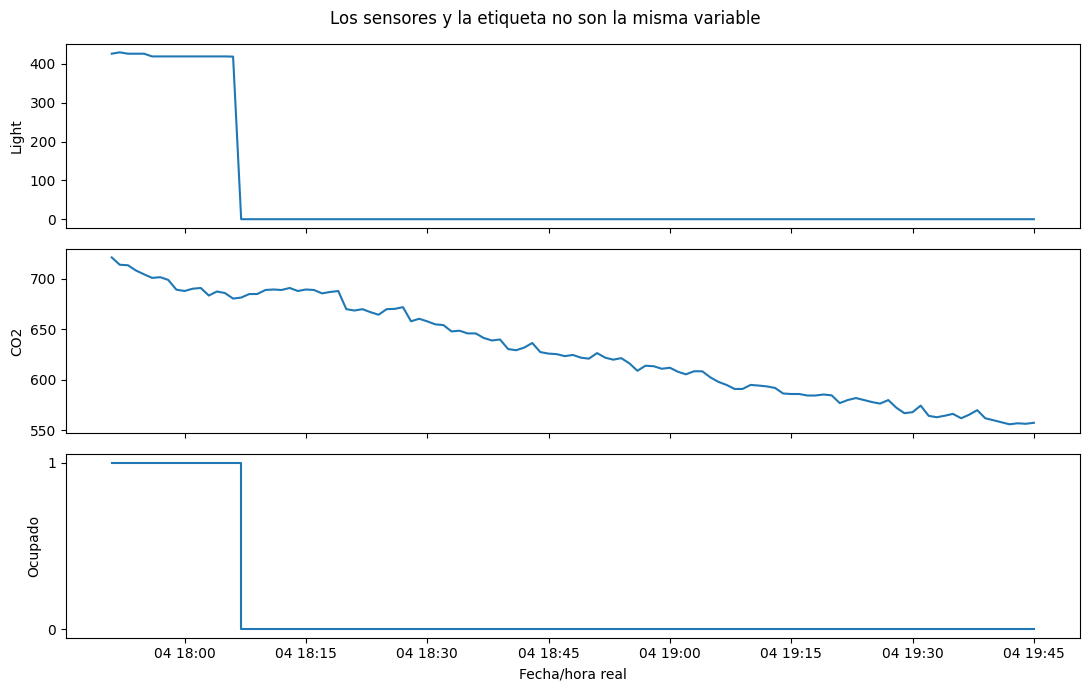

In [ ]:
# Observar una transición real en entrenamiento, no elegir ejemplos de prueba para ajustar el modelo.
cambios=np.flatnonzero(np.diff(train_df.Occupancy.to_numpy())!=0)
centro=int(cambios[0]) if len(cambios) else len(train_df)//2
vista=train_df.iloc[max(0,centro-70):centro+100]
fig,axs=plt.subplots(3,1,figsize=(11,7),sharex=True)
for ax,col in zip(axs[:2],['Light','CO2']):
    ax.plot(vista.date,vista[col]); ax.set_ylabel(col)
axs[2].step(vista.date,vista.Occupancy,where='post'); axs[2].set_ylabel('Ocupado'); axs[2].set_yticks([0,1]);
axs[2].set_xlabel('Fecha/hora real'); fig.suptitle('Los sensores y la etiqueta no son la misma variable')
plt.tight_layout(); plt.show()

**Qué mirar:** ¿cambia la luz al cambiar la ocupación? ¿El CO₂ responde inmediatamente? La asociación ayuda a clasificar, pero no demuestra causalidad. Que la luz resulte suficiente en este lugar puede limitar la ventaja de una red recurrente.

## 3. ¿Qué entra exactamente en la red?
Una muestra contiene una matriz de **16 registros × 5 características**. Normalizamos con media y desviación calculadas solo en entrenamiento. Después creamos ventanas dentro de cada partición.

Para rapidez, entrenamiento avanza cuatro registros entre ventanas; validación y prueba avanzan uno. Las ventanas se solapan dentro de una partición, por lo que sus errores no son observaciones estadísticas independientes. Cada ventana de prueba tiene un último registro distinto; no contamos la misma etiqueta final varias veces.

Las mediciones son aproximadamente por minuto. Conservamos el paso por registro del ejemplo; no afirmamos modelar segundos exactos. El código excluye ventanas que atraviesan huecos mayores a dos minutos.

In [ ]:
SEQ=16; BATCH=64; UNITS=16; MAX_EPOCHS=12; PATIENCE=4; LR=0.005
media=train_df[FEATURES].mean().to_numpy(np.float32)
escala=train_df[FEATURES].std(ddof=0).to_numpy(np.float32)
escala=np.maximum(escala,1e-6)
def ventanas(df,stride=1,archivo=''):
    valores=(df[FEATURES].to_numpy(np.float32)-media)/escala
    gaps=df.date.diff().dt.total_seconds().fillna(60).to_numpy()
    X=[]; y=[]; filas=[]
    for fin in range(SEQ-1,len(df),stride):
        inicio=fin-SEQ+1
        if (gaps[inicio+1:fin+1]>120).any(): continue
        X.append(valores[inicio:fin+1]); y.append(int(df.Occupancy.iloc[fin]))
        filas.append({'archivo':archivo,'fila_final':fin,'fecha':str(df.date.iloc[fin]),
                     **df.iloc[fin][FEATURES].to_dict()})
    if not X: raise ValueError('No hay ventanas válidas; revisar longitud y fechas')
    return np.stack(X),np.array(y,np.int64),pd.DataFrame(filas)
Xtr,ytr,_=ventanas(train_df,4,'train')
Xva,yva,_=ventanas(val_df,1,'validation')
partes=[ventanas(df,1,f'prueba_{i+1}') for i,df in enumerate(prueba_archivos)]
Xte=np.concatenate([p[0] for p in partes]); yte=np.concatenate([p[1] for p in partes])
meta_test=pd.concat([p[2] for p in partes],ignore_index=True)
assert not meta_test.duplicated(['archivo','fila_final']).any()
generador=torch.Generator().manual_seed(SEED)
train_loader=DataLoader(TensorDataset(torch.from_numpy(Xtr),torch.from_numpy(ytr)),
                        batch_size=BATCH,shuffle=True,generator=generador)
print('Entrenamiento:',Xtr.shape,'Validación:',Xva.shape,'Prueba:',Xte.shape)
print('Convención: [secuencias, registros por secuencia, características]')
display(pd.DataFrame(Xtr[0],columns=FEATURES).round(2))
print('Etiqueta de la primera secuencia:',ytr[0], '→', 'ocupado' if ytr[0] else 'vacío')

Entrenamiento: (1625, 16, 5) Validación: (1614, 16, 5) Prueba: (12387, 16, 5)
Convención: [secuencias, registros por secuencia, características]


,Temperature,Humidity,Light,CO2,HumidityRatio
0,2.40,0.81,1.69,1.01,2.06
1,2.37,0.81,1.71,0.97,2.05
2,2.37,0.80,1.69,0.97,2.04
3,2.37,0.79,1.69,0.94,2.03
4,2.33,0.79,1.69,0.92,2.00
5,2.33,0.79,1.65,0.90,2.00
6,2.33,0.79,1.65,0.91,2.00
7,2.33,0.79,1.65,0.89,2.00
8,2.33,0.79,1.65,0.84,2.00
9,2.30,0.79,1.65,0.83,1.98


Etiqueta de la primera secuencia: 1 → ocupado


## 4. Construir una LTC real
Usamos cinco entradas, 16 unidades recurrentes LTC y una capa lineal que produce dos puntuaciones (vacío/ocupado). Softmax convierte esas puntuaciones en probabilidades del modelo. No son probabilidades calibradas de seguridad.

La LTC combina entrada e historia; su solucionador realiza seis subpasos por registro. **Estos subpasos no son épocas**. La capa lineal interpreta el estado final de la secuencia. El estado se inicia en cero en cada ventana: no transportamos memoria entre archivos ni entre personas.

El número de unidades permanece fijo. Lo variable durante el uso es su estado y su dinámica; los parámetros cambian solo durante entrenamiento.

In [ ]:
class DetectorOcupacion(nn.Module):
    def __init__(self):
        super().__init__()
        self.ltc=LTC(input_size=5,units=UNITS,batch_first=True,
                     return_sequences=True,mixed_memory=False,ode_unfolds=6)
        self.salida=nn.Linear(UNITS,2)
    def forward(self,x):
        estados,ultimo=self.ltc(x)   # [lote,16,unidades]
        return self.salida(estados[:,-1,:])
modelo=DetectorOcupacion().to(DEVICE)
print(modelo)
print('Parámetros aprendibles:',sum(p.numel() for p in modelo.parameters() if p.requires_grad))
with torch.no_grad():
    salida=modelo(torch.from_numpy(Xtr[:2]).to(DEVICE))
print('Dos secuencias →',tuple(salida.shape),'puntuaciones:')
print(salida.cpu().numpy())

DetectorOcupacion(
  (ltc): LTC(
    (rnn_cell): LTCCell(
      (make_positive_fn): Softplus(beta=1.0, threshold=20.0)
      (_clip): ReLU()
    )
  )
  (salida): Linear(in_features=16, out_features=2, bias=True)
)
Parámetros aprendibles: 1468
Dos secuencias → (2, 2) puntuaciones:
[[ 0.18665531 -0.10621087]
 [ 0.17422512 -0.06220984]]


## 5. Guardar la predicción inicial y ver un gradiente
Antes de entrenar guardamos los parámetros iniciales. Mostramos las primeras predicciones en **validación**. La prueba se reserva para después de seleccionar el checkpoint.

La pérdida de entropía cruzada penaliza las puntuaciones incorrectas. `backward()` calcula derivadas respecto de los parámetros. Adam utilizará esas derivadas para ajustarlos. Una norma de gradiente distinta de cero comprueba que la señal de aprendizaje llega a la LTC; no garantiza que el modelo sea bueno.

In [ ]:
@torch.no_grad()
def probabilidades(red,X,batch_size=256):
    red.eval(); salida=[]
    for inicio in range(0,len(X),batch_size):
        logits=red(torch.from_numpy(X[inicio:inicio+batch_size]).to(DEVICE))
        salida.append(torch.softmax(logits,dim=1)[:,1].cpu().numpy())
    return np.concatenate(salida)
estado_inicial=copy.deepcopy(modelo.state_dict())
p_val_inicial=probabilidades(modelo,Xva)
display(pd.DataFrame({'real_validacion':yva[:8],
    'p_ocupado_antes':p_val_inicial[:8].round(3),
    'prediccion_antes':(p_val_inicial[:8]>=.5).astype(int)}))
criterio=nn.CrossEntropyLoss()
xb,yb=next(iter(train_loader)); modelo.train(); modelo.zero_grad(set_to_none=True)
perdida=criterio(modelo(xb.to(DEVICE)),yb.to(DEVICE)); perdida.backward()
GRADIENTES=pd.DataFrame([{'parametro':nombre,'forma':str(tuple(p.shape)),
 'norma_gradiente':float(p.grad.norm().cpu())}
 for nombre,p in modelo.named_parameters() if p.grad is not None])
display(GRADIENTES.head(12)); assert GRADIENTES.norma_gradiente.sum()>0
modelo.zero_grad(set_to_none=True)

,real_validacion,p_ocupado_antes,prediccion_antes
0,0,0.485,0
1,0,0.486,0
2,0,0.487,0
3,0,0.487,0
4,0,0.487,0
5,0,0.487,0
6,0,0.488,0
7,0,0.488,0


,parametro,forma,norma_gradiente
0,ltc.rnn_cell.gleak,"(16,)",0.010188
1,ltc.rnn_cell.vleak,"(16,)",0.039569
2,ltc.rnn_cell.cm,"(16,)",0.000011
3,ltc.rnn_cell.sigma,"(16, 16)",0.004518
4,ltc.rnn_cell.mu,"(16, 16)",0.100983
5,ltc.rnn_cell.w,"(16, 16)",0.035084
6,ltc.rnn_cell.erev,"(16, 16)",0.067113
7,ltc.rnn_cell.sensory_sigma,"(5, 16)",0.000894
8,ltc.rnn_cell.sensory_mu,"(5, 16)",0.022333
9,ltc.rnn_cell.sensory_w,"(5, 16)",0.009096


## 6. Entrenar: aquí ocurre el aprendizaje
Esta celda **ejecuta** la red. En cada lote: predicción → pérdida → gradientes → actualización de Adam. Al terminar cada época evaluamos validación y conservamos el modelo con menor pérdida de validación. Si no mejora durante cuatro épocas paramos.

Los datos de prueba no participan en esta selección. El tiempo depende del equipo. Cada fila impresa muestra avances reales; no hay resultados prefabricados. No esperamos que todos los indicadores mejoren en cada época.

In [ ]:
# Restaurar para que volver a ejecutar esta celda empiece desde el mismo modelo inicial.
modelo.load_state_dict(estado_inicial)
optimizador=torch.optim.Adam(modelo.parameters(),lr=LR)
historia=[]; mejor=float('inf'); sin_mejora=0; mejor_estado=None
inicio_total=time.time()
for epoca in range(1,MAX_EPOCHS+1):
    inicio=time.time(); modelo.train(); suma=0.; aciertos=0; n=0
    for xb,yb in train_loader:
        xb,yb=xb.to(DEVICE),yb.to(DEVICE)
        optimizador.zero_grad(set_to_none=True)
        logits=modelo(xb)
        loss=criterio(logits,yb)
        if not torch.isfinite(loss): raise RuntimeError('Pérdida no finita; detener y revisar')
        loss.backward()                    # Calcula los gradientes de la LTC y su salida.
        optimizador.step()                 # Adam modifica los parámetros.
        # ncps 1.0.1 ofrece restricciones positivas para conductancias/capacidades.
        modelo.ltc.rnn_cell.apply_weight_constraints()
        suma+=loss.item()*len(yb); aciertos+=(logits.argmax(1)==yb).sum().item(); n+=len(yb)
    pv=probabilidades(modelo,Xva)
    val_loss=log_loss(yva,np.column_stack([1-pv,pv]),labels=[0,1])
    fila={'epoca':epoca,'train_loss':suma/n,'val_loss':val_loss,
          'train_accuracy':aciertos/n,'val_accuracy':accuracy_score(yva,pv>=.5),
          'segundos':time.time()-inicio}
    historia.append(fila)
    print(f"Época {epoca:02d} | pérdida train {fila['train_loss']:.4f} | val {val_loss:.4f} | "
          f"aciertos train {fila['train_accuracy']:.1%} | val {fila['val_accuracy']:.1%} | {fila['segundos']:.1f}s",flush=True)
    if val_loss<mejor-1e-5:
        mejor=val_loss; mejor_epoca=epoca; mejor_estado=copy.deepcopy(modelo.state_dict()); sin_mejora=0
    else: sin_mejora+=1
    if sin_mejora>=PATIENCE:
        print('Parada por falta de mejora en validación.'); break
modelo.load_state_dict(mejor_estado); modelo.eval()
H=pd.DataFrame(historia); H.to_csv(ROOT/'historia.csv',index=False)
assert any(not torch.equal(estado_inicial[k],mejor_estado[k]) for k in mejor_estado)
print(f'Modelo seleccionado: época {mejor_epoca}. Tiempo total: {time.time()-inicio_total:.1f}s')

Época 01 | pérdida train 0.4693 | val 0.7435 | aciertos train 80.7% | val 63.6% | 9.7s
Época 02 | pérdida train 0.2916 | val 0.4119 | aciertos train 85.0% | val 63.6% | 6.5s
Época 03 | pérdida train 0.1057 | val 0.3921 | aciertos train 96.7% | val 86.7% | 2.7s
Época 04 | pérdida train 0.0774 | val 0.0886 | aciertos train 97.9% | val 98.1% | 2.5s
Época 05 | pérdida train 0.0563 | val 0.1457 | aciertos train 98.5% | val 97.7% | 2.4s
Época 06 | pérdida train 0.0497 | val 0.2112 | aciertos train 98.6% | val 96.7% | 2.4s
Época 07 | pérdida train 0.0493 | val 0.1634 | aciertos train 98.6% | val 97.5% | 3.9s
Época 08 | pérdida train 0.0478 | val 0.1682 | aciertos train 98.6% | val 97.5% | 2.5s
Parada por falta de mejora en validación.
Modelo seleccionado: época 4. Tiempo total: 32.7s


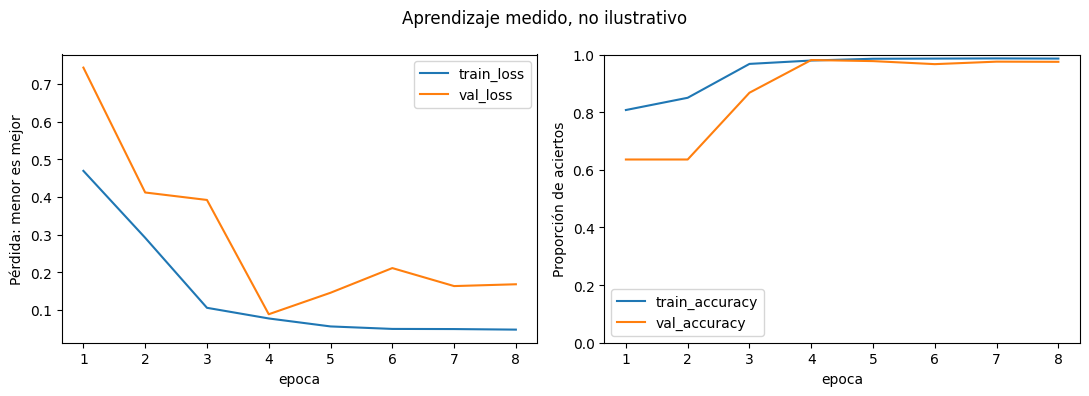

La pérdida mide la calidad de las puntuaciones; accuracy solo cuenta decisiones correctas.


In [ ]:
fig,axs=plt.subplots(1,2,figsize=(11,4))
H.plot(x='epoca',y=['train_loss','val_loss'],ax=axs[0]); axs[0].set_ylabel('Pérdida: menor es mejor')
H.plot(x='epoca',y=['train_accuracy','val_accuracy'],ax=axs[1]); axs[1].set_ylabel('Proporción de aciertos')
axs[1].set_ylim(0,1); fig.suptitle('Aprendizaje medido, no ilustrativo')
plt.tight_layout(); plt.savefig(ROOT/'aprendizaje.png',dpi=130); plt.show()
print('La pérdida mide la calidad de las puntuaciones; accuracy solo cuenta decisiones correctas.')

## 7. Ahora sí: prueba, antes y después
Una vez seleccionado el modelo, evaluamos los archivos de prueba. Reconstruimos el modelo inicial para comparar ambos sobre **exactamente las mismas secuencias**. Mostramos además dos referencias: siempre predecir la clase más frecuente de entrenamiento y regresión logística sobre las cinco características del último registro.

Accuracy: proporción de aciertos. Sensibilidad: proporción de registros ocupados detectados. Precisión: de los registros que llamamos ocupados, cuántos lo están. F1 combina precisión y sensibilidad. El umbral es 0.5, fijado antes de mirar prueba. Una exactitud alta de logística no invalida LTC; puede indicar que esta tarea se resuelve con la medición actual.

,accuracy,precision_ocupado,sensibilidad_ocupado,F1_ocupado
modelo,,,,
Mayoritaria,0.7585,0.0000,0.0000,0.0000
Logística,0.8762,0.7228,0.7907,0.7552
LTC antes,0.6479,0.0000,0.0000,0.0000
LTC después,0.9792,0.9237,0.9960,0.9585


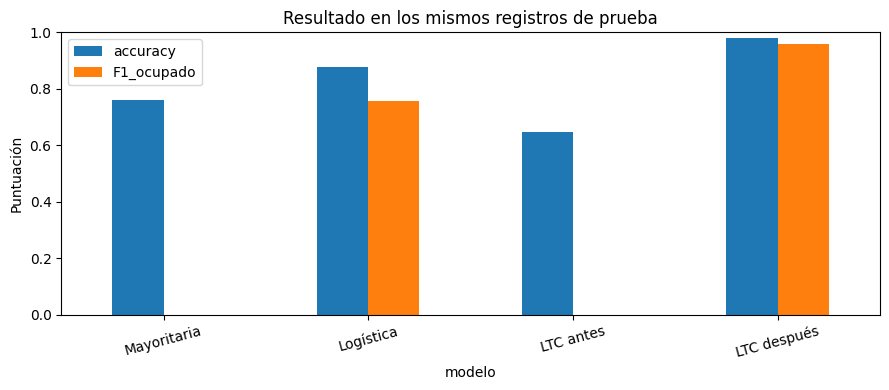

Cambio en accuracy LTC: 33.13 puntos porcentuales


In [ ]:
inicial=DetectorOcupacion().to(DEVICE); inicial.load_state_dict(estado_inicial)
p_antes=probabilidades(inicial,Xte); p_despues=probabilidades(modelo,Xte)
logistica=LogisticRegression(max_iter=1000,random_state=SEED)
logistica.fit(Xtr[:,-1,:],ytr)  # Mismas ventanas de entrenamiento, último registro.
p_logistica=logistica.predict_proba(Xte[:,-1,:])[:,1]
clase_mayoritaria=int(np.bincount(ytr).argmax())
p_mayoritaria=np.full(len(yte),float(clase_mayoritaria))
filas=[]
for nombre,p in [('Mayoritaria',p_mayoritaria),('Logística',p_logistica),
                  ('LTC antes',p_antes),('LTC después',p_despues)]:
    pred=(p>=.5).astype(int)
    filas.append({'modelo':nombre,'accuracy':accuracy_score(yte,pred),
        'precision_ocupado':precision_score(yte,pred,zero_division=0),
        'sensibilidad_ocupado':recall_score(yte,pred,zero_division=0),
        'F1_ocupado':f1_score(yte,pred,zero_division=0)})
RESULTADOS=pd.DataFrame(filas).set_index('modelo'); display(RESULTADOS.round(4))
RESULTADOS.to_csv(ROOT/'metricas_prueba.csv')
RESULTADOS[['accuracy','F1_ocupado']].plot.bar(rot=15,ylim=(0,1),figsize=(9,4))
plt.title('Resultado en los mismos registros de prueba'); plt.ylabel('Puntuación'); plt.tight_layout(); plt.show()
print('Cambio en accuracy LTC:',round(100*(RESULTADOS.loc['LTC después','accuracy']-RESULTADOS.loc['LTC antes','accuracy']),2),'puntos porcentuales')

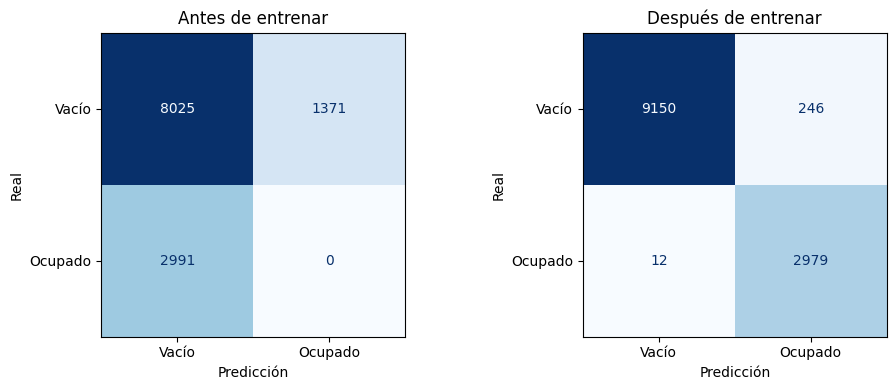

              precision    recall  f1-score   support

       Vacío       1.00      0.97      0.99      9396
     Ocupado       0.92      1.00      0.96      2991

    accuracy                           0.98     12387
   macro avg       0.96      0.98      0.97     12387
weighted avg       0.98      0.98      0.98     12387



In [ ]:
fig,axs=plt.subplots(1,2,figsize=(10,4))
for ax,p,titulo in zip(axs,[p_antes,p_despues],['Antes de entrenar','Después de entrenar']):
    cm=confusion_matrix(yte,p>=.5,labels=[0,1])
    ConfusionMatrixDisplay(cm,display_labels=['Vacío','Ocupado']).plot(ax=ax,colorbar=False,cmap='Blues')
    ax.set_title(titulo); ax.set_xlabel('Predicción'); ax.set_ylabel('Real')
plt.tight_layout(); plt.savefig(ROOT/'confusion.png',dpi=130); plt.show()
print(classification_report(yte,p_despues>=.5,target_names=['Vacío','Ocupado'],zero_division=0))

**Cómo leerla:** diagonal = aciertos. “Real ocupado / predicho vacío” = omisión de ocupación. “Real vacío / predicho ocupado” = falsa alarma. Su importancia depende del uso. Esta aplicación docente no debe tratarse como un sistema de seguridad validado.

## 8. Resultado tangible: una secuencia, una decisión
Ahora podemos señalar un momento real y decir: “Estas son las 16 mediciones que recibió la LTC; esta era la etiqueta; esto respondió antes y después”. El siguiente gráfico usa la primera transición del primer archivo de prueba: una regla fija para elegir un segmento, no el tramo con mejores resultados.

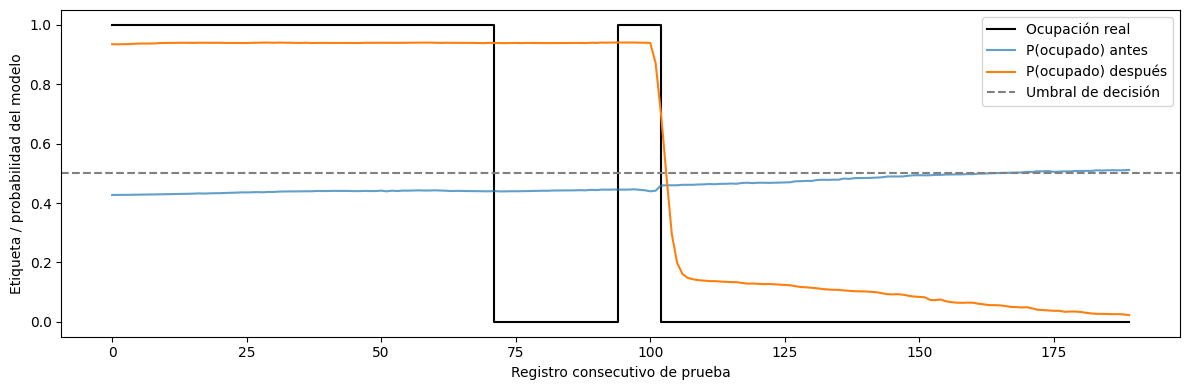

,fecha,Light,CO2,real,p_antes,p_despues,prediccion,correcto
109,2015-02-02 16:23:00,444.000,1018.000,1,0.427,0.935,1,True
110,2015-02-02 16:24:00,435.429,1015.143,1,0.427,0.934,1,True
111,2015-02-02 16:25:00,434.000,1006.333,1,0.428,0.935,1,True
112,2015-02-02 16:25:59,432.000,1002.600,1,0.428,0.935,1,True
113,2015-02-02 16:27:00,438.000,993.200,1,0.428,0.936,1,True
114,2015-02-02 16:27:59,439.000,983.333,1,0.428,0.937,1,True
115,2015-02-02 16:28:59,432.000,976.200,1,0.429,0.937,1,True
116,2015-02-02 16:30:00,432.750,980.750,1,0.429,0.937,1,True
117,2015-02-02 16:31:00,434.000,971.333,1,0.429,0.937,1,True
118,2015-02-02 16:32:00,444.000,966.667,1,0.429,0.939,1,True


In [ ]:
PREDICCIONES=meta_test.copy()
PREDICCIONES['real']=yte; PREDICCIONES['p_antes']=p_antes; PREDICCIONES['p_despues']=p_despues
PREDICCIONES['prediccion']=(p_despues>=.5).astype(int)
PREDICCIONES['correcto']=PREDICCIONES.prediccion==yte
PREDICCIONES.to_csv(ROOT/'predicciones.csv',index=False)
idx=np.flatnonzero(meta_test.archivo.to_numpy()=='prueba_1')
cambios=np.flatnonzero(np.diff(yte[idx])!=0)
centro=int(cambios[0]) if len(cambios) else len(idx)//2
seleccion=idx[max(0,centro-70):centro+120]
fig,ax=plt.subplots(figsize=(12,4))
ax.step(np.arange(len(seleccion)),yte[seleccion],where='post',color='black',label='Ocupación real')
ax.plot(p_antes[seleccion],label='P(ocupado) antes',alpha=.7)
ax.plot(p_despues[seleccion],label='P(ocupado) después')
ax.axhline(.5,color='gray',ls='--',label='Umbral de decisión')
ax.set_xlabel('Registro consecutivo de prueba'); ax.set_ylabel('Etiqueta / probabilidad del modelo')
ax.set_ylim(-.05,1.05); ax.legend(); plt.tight_layout(); plt.savefig(ROOT/'predicciones_temporales.png',dpi=130); plt.show()
display(PREDICCIONES.iloc[seleccion[:12]][['fecha','Light','CO2','real','p_antes','p_despues','prediccion','correcto']].round(3))

**2015-02-02 17:57:59 · prueba_1** — Real: **ocupado**. LTC antes: **44.5%** ocupado; después: **94.0%**. Decisión: **ocupado**.

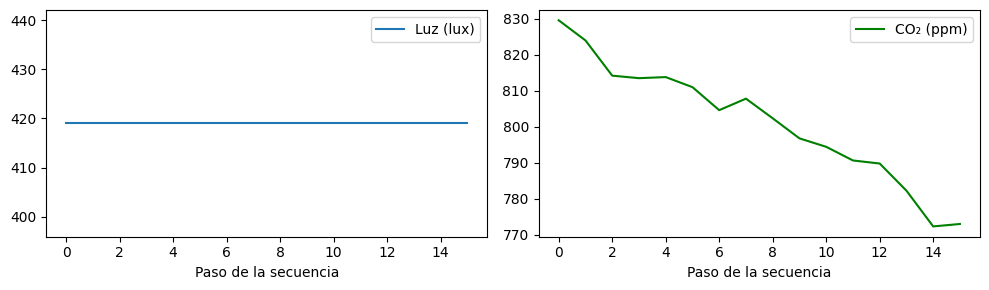

,date,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
0,2015-02-02 17:43:00,22.5000,25.000000,419.0,829.600000,0.004212,0
1,2015-02-02 17:44:00,22.5000,25.000000,419.0,824.000000,0.004212,0
2,2015-02-02 17:44:59,22.5000,24.912000,419.0,814.200000,0.004197,0
3,2015-02-02 17:45:59,22.5000,24.890000,419.0,813.500000,0.004194,0
4,2015-02-02 17:47:00,22.5000,24.890000,419.0,813.800000,0.004194,0
5,2015-02-02 17:48:00,22.5000,24.890000,419.0,811.000000,0.004194,0
6,2015-02-02 17:49:00,22.4780,24.870000,419.0,804.600000,0.004185,0
7,2015-02-02 17:50:00,22.4560,24.830000,419.0,807.800000,0.004172,0
8,2015-02-02 17:51:00,22.5000,24.856667,419.0,802.333333,0.004188,0
9,2015-02-02 17:51:59,22.4175,24.747500,419.0,796.750000,0.004149,0


In [ ]:
# Esta función funciona incluso si Colab no muestra widgets.
def mostrar_caso(indice=0):
    i=int(indice); fila=meta_test.iloc[i]
    origen=prueba_archivos[int(fila.archivo.split('_')[-1])-1]
    fin=int(fila.fila_final); secuencia=origen.iloc[fin-SEQ+1:fin+1]
    display(Markdown(f"**{fila.fecha} · {fila.archivo}** — Real: **{'ocupado' if yte[i] else 'vacío'}**. "
        f"LTC antes: **{p_antes[i]:.1%}** ocupado; después: **{p_despues[i]:.1%}**. "
        f"Decisión: **{'ocupado' if p_despues[i]>=.5 else 'vacío'}**."))
    fig,axs=plt.subplots(1,2,figsize=(10,3))
    axs[0].plot(secuencia.Light.to_numpy(),label='Luz (lux)'); axs[0].legend(); axs[0].set_xlabel('Paso de la secuencia')
    axs[1].plot(secuencia.CO2.to_numpy(),color='green',label='CO₂ (ppm)'); axs[1].legend(); axs[1].set_xlabel('Paso de la secuencia')
    plt.tight_layout(); plt.show()
    display(secuencia[['date',*FEATURES,'Occupancy']].reset_index(drop=True))
mostrar_caso(int(seleccion[len(seleccion)//2]))

In [ ]:
# Explorador opcional. La tabla y los gráficos anteriores siempre quedan disponibles.
try:
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass
try:
    import ipywidgets as widgets
    control=widgets.IntSlider(value=0,min=0,max=len(yte)-1,step=1,
                              description='Caso',continuous_update=False)
    display(widgets.VBox([control,widgets.interactive_output(mostrar_caso,{'indice':control})]))
except Exception as e:
    print('El explorador no está disponible. Usa mostrar_caso(100). Detalle:',str(e))

## 9. Ver los fallos y sus límites
No basta con mostrar un acierto. Listamos errores y distinguimos falsas alarmas y omisiones. Se muestran primero los errores con mayor seguridad asignada a la clase equivocada. Eso no es un criterio para reajustar el modelo con prueba: sirve para describirlo y planear un nuevo estudio.

,fecha,archivo,Light,CO2,real,prediccion,p_despues,tipo
1022,2015-02-03 07:36:00,prueba_1,217.20,441.600,1,0,0.005,Omisión: había ocupación
2464,2015-02-04 07:38:00,prueba_1,311.75,474.750,1,0,0.018,Omisión: había ocupación
3702,2015-02-12 08:35:00,prueba_2,444.00,702.333,0,1,0.980,Falsa alarma: estaba vacío
3701,2015-02-12 08:34:00,prueba_2,442.75,681.750,0,1,0.980,Falsa alarma: estaba vacío
3703,2015-02-12 08:36:00,prueba_2,444.00,707.000,0,1,0.980,Falsa alarma: estaba vacío
3700,2015-02-12 08:32:59,prueba_2,454.00,652.500,0,1,0.979,Falsa alarma: estaba vacío
9477,2015-02-16 08:50:00,prueba_2,405.00,872.500,0,1,0.973,Falsa alarma: estaba vacío
9475,2015-02-16 08:48:00,prueba_2,397.00,870.750,0,1,0.973,Falsa alarma: estaba vacío
9476,2015-02-16 08:49:00,prueba_2,405.00,869.000,0,1,0.973,Falsa alarma: estaba vacío
4157,2015-02-12 16:09:59,prueba_2,191.50,534.500,1,0,0.027,Omisión: había ocupación


Errores: 258 de 12387


**2015-02-02 17:34:00 · prueba_1** — Real: **vacío**. LTC antes: **44.0%** ocupado; después: **93.9%**. Decisión: **ocupado**.

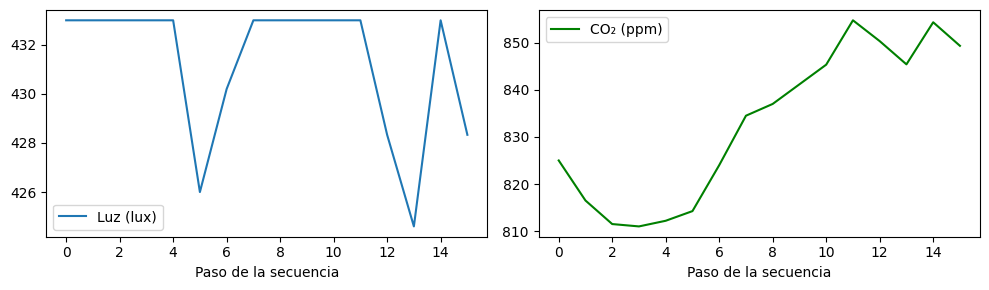

,date,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
0,2015-02-02 17:19:00,22.540,24.890000,433.000000,825.000000,0.004204,1
1,2015-02-02 17:19:59,22.500,24.865000,433.000000,816.500000,0.004189,1
2,2015-02-02 17:21:00,22.500,24.917500,433.000000,811.500000,0.004198,1
3,2015-02-02 17:22:00,22.500,24.911667,433.000000,811.000000,0.004197,1
4,2015-02-02 17:23:00,22.560,24.810000,433.000000,812.200000,0.004196,1
5,2015-02-02 17:23:59,22.525,24.890000,426.000000,814.250000,0.004200,1
6,2015-02-02 17:25:00,22.520,24.976000,430.200000,824.000000,0.004213,1
7,2015-02-02 17:25:59,22.575,25.075000,433.000000,834.500000,0.004245,1
8,2015-02-02 17:26:59,22.600,25.000000,433.000000,837.000000,0.004238,1
9,2015-02-02 17:28:00,22.600,25.021429,433.000000,841.166667,0.004242,1


In [ ]:
errores=PREDICCIONES.loc[~PREDICCIONES.correcto].copy()
errores['tipo']=np.where(errores.real==1,'Omisión: había ocupación','Falsa alarma: estaba vacío')
errores['seguridad_equivocada']=np.where(errores.prediccion==1,errores.p_despues,1-errores.p_despues)
display(errores.sort_values('seguridad_equivocada',ascending=False)
        [['fecha','archivo','Light','CO2','real','prediccion','p_despues','tipo']].head(12).round(3))
print('Errores:',len(errores),'de',len(PREDICCIONES))
if len(errores): mostrar_caso(int(errores.index[0]))
else: print('No hubo errores en este conjunto; eso no garantiza generalización a otra habitación.')

## 10. ¿Qué comprobamos y qué falta?
- Ejecutamos una **red LTC entrenable**, con pérdida, gradientes y actualización de parámetros visibles.
- Comparamos el estado inicial y el modelo seleccionado con validación, usando la misma prueba.
- Evaluamos referencias simples: una LTC puede mejorar al entrenarse sin superar a una regresión.
- Los pasos de cada secuencia tienen orden, pero la prueba procede de la misma aplicación; no demuestra generalización a otro edificio o sensor.
- El protocolo del artículo y este protocolo son distintos. Una diferencia frente a su tabla no demuestra un fallo de reproducción ni una mejora científica.
- Las ventanas temporales se correlacionan. Para intervalos de confianza harían falta bloques temporales/unidades independientes, no tratar cada ventana como una persona distinta.

**Discusión:** ¿cuánto aporta la historia frente a la luz actual? Para responder haría falta comparar con una ablación entrenada sin historia y repetir con varios periodos/semillas. Cambiar de orden solo en prueba altera la distribución y no basta para demostrar el valor de la memoria.

### Trasladarlo a tus áreas
El mismo formato puede representar ensayos de una prueba psicológica o visitas/vuelos con mediciones extraídas de imágenes. Cambian la etiqueta, la unidad independiente y la validación. En psicología se separan participantes; en imágenes clínicas, pacientes; en drones, parcelas y campañas. Para una imagen aislada suele hacer falta un extractor espacial, no inventar una secuencia temporal. Aquí no se validan diagnósticos ni crecimiento vegetal.

## 11. Guardar el modelo, las predicciones y una muestra reutilizable
El archivo del modelo conserva pesos, configuración y normalización. El ZIP incluye el CSV de prueba, las métricas, la historia y gráficos. El bloque comprueba que guardar y recargar reproduce una predicción sobre el mismo ejemplo. Para usar datos nuevos deben tener las mismas cinco columnas, escala original y orden temporal.

En Colab la descarga se activa cambiando `DESCARGAR_ZIP` a `True`; el ZIP también queda en la carpeta de archivos.

In [ ]:
checkpoint={'state_dict':{k:v.detach().cpu() for k,v in modelo.state_dict().items()},
            'features':FEATURES,'media':media.tolist(),'escala':escala.tolist(),
            'seq':SEQ,'units':UNITS,'mejor_epoca':mejor_epoca,'seed':SEED}
torch.save(checkpoint,ROOT/'modelo_ltc.pt')
# Recargar solo nuestro propio checkpoint, con parámetros y metadatos simples.
cargado=torch.load(ROOT/'modelo_ltc.pt',map_location=DEVICE,weights_only=True)
recargado=DetectorOcupacion().to(DEVICE); recargado.load_state_dict(cargado['state_dict'])
assert np.allclose(probabilidades(recargado,Xte[:3]),p_despues[:3],atol=1e-6)
np.savez_compressed(ROOT/'muestra_prueba.npz',X=Xte[:100],y=yte[:100])
config={'python':platform.python_version(),'torch':torch.__version__,'ncps':version('ncps'),
 'numpy':np.__version__,'pandas':pd.__version__,'seed':SEED,'seq':SEQ,'units':UNITS,
 'epocas_ejecutadas':len(H),'mejor_epoca':mejor_epoca,'lr':LR,'batch':BATCH,
 'dispositivo':str(DEVICE),'zip_sha256':hashlib.sha256(zip_path.read_bytes()).hexdigest(),
 'alcance':'Reproducción didáctica de la aplicación Occupancy; no réplica numérica del protocolo original'}
(ROOT/'configuracion.json').write_text(json.dumps(config,indent=2))
archivo=shutil.make_archive(str(ROOT.parent/'LTC_ocupacion_resultados'),'zip',ROOT)
print('Modelo recargado: predicciones verificadas. ZIP:',archivo)
DESCARGAR_ZIP=False
if DESCARGAR_ZIP:
    try:
        from google.colab import files
        files.download(archivo)
    except ImportError: print('Fuera de Colab: el ZIP está en la ruta indicada.')

Modelo recargado: predicciones verificadas. ZIP: /content/LTC_ocupacion_resultados.zip


## Fuentes
- Hasani, R., Lechner, M., Amini, A., Rus, D., & Grosu, R. (2021). *Liquid time-constant networks*. [Artículo y suplemento](https://arxiv.org/pdf/2006.04439).
- [Código original del artículo](https://github.com/raminmh/liquid_time_constant_networks): referencia histórica de la aplicación.
- [ncps](https://github.com/mlech26l/ncps) y [API PyTorch LTC](https://ncps.readthedocs.io/en/latest/api/torch.html): implementación utilizada, versión fijada en la instalación.
- Candanedo, L. (2016). *Occupancy Detection* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5X01N. [Datos y documentación](https://archive.ics.uci.edu/dataset/357/occupancy+detection). Atribución CC BY 4.0.

**Lectura del resultado:** “La LTC pasó de ____ a ____ en accuracy, con ____ falsas alarmas y ____ omisiones. Frente a logística ____. Estos resultados corresponden a este conjunto y a esta semilla; proponemos ____ como siguiente comprobación”.

### Comprobación de esta versión
Se ejecutaron todas las celdas, en orden, en una sesión Python/IPython de preparación: Python 3.12.14, PyTorch 2.14.1 CPU, ncps 1.0.1. El entrenamiento se detuvo tras 8 épocas y seleccionó la época 4 por validación. Sobre 12.387 ventanas de prueba, accuracy pasó de **64,79%** a **97,92%**. Estos valores son una corrida medida, no una promesa de resultados idénticos en otros equipos.

Las salidas gráficas y tablas incluidas corresponden a esas mediciones. Se verificó que el modelo guardado y recargado conserva sus predicciones. **No se ejecutó en una sesión del servicio web Colab**; el cuaderno usa su Python principal y no requiere reinicios ni entornos antiguos. Al ejecutar en Colab se volverán a medir resultados con las versiones allí disponibles.